# Porównania na spotkanie: co badamy i przykładowe wyniki

Notatnik puszcza **krótkie przebiegi bez GUI** (4 h symulacji od poniedziałku 8:00, kilka seedów,
równolegle) przez `src/experiments/build.py` i `record.py`, czyli te same parametry co pasek
boczny wizualizacji. Całość liczy się kilka minut; wyniki trafiają do `output/porownania/*.csv`
i przy ponownym uruchomieniu są wczytywane, a nie liczone od nowa.

Wyniki są **przykładowe** (3–5 seedów, 4 h zamiast doby). Pełne liczenie robi runner scenariuszy
(`make scenarios`). Uzasadnienie wszystkich ustawień: `docs/decyzje_dane_olist.md`, sekcja 10.

**Skala obciążenia (suwak „Natężenie”)**: prawdziwy Olist to ok. 123 zamówienia dziennie, za mało
dla magazynu Kiva, więc:

| Natężenie | Znaczenie | Zamówień/h (8:00 → 12:00) |
| --- | --- | --- |
| ×1 | zwykły dzień (Olist ×10, jak w scenariuszach) | 38 → 90 |
| ×5 | wzmożony ruch (połowa Black Friday) | 190 → 450 |
| ×9,5 | szczyt: Black Friday 2017 (1166 zamówień wobec ~123 w średni dzień) | 360 → 855 |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.experiments.build import LAYOUTS, olist_stats
from src.experiments.compare import run_grid, summary
from src.plotting.style import CATEGORICAL, INK_SECONDARY, style

style()
OUT = ROOT / "output" / "porownania"
JOBS = 4  # procesy równolegle; zmniejsz na słabszym komputerze
pd.set_option("display.precision", 1)
assert olist_stats() is not None, "Brak danych Olist: uv run data/download_olist.py"

LOAD = {1.0: "zwykły dzień ×1", 5.0: "wzmożony ×5", 9.5: "Black Friday ×9,5"}


def bars(ax, table, group, series, metric, labels=None, colors=None):
    """Grouped bars with 95% intervals: one group per value of ``group``."""
    groups = list(dict.fromkeys(table[group]))
    names = list(dict.fromkeys(table[series]))
    width = 0.8 / len(names)
    for i, name in enumerate(names):
        part = table[table[series] == name].set_index(group).reindex(groups)
        x = np.arange(len(groups)) + (i - (len(names) - 1) / 2) * width
        ax.bar(x, part[metric], width, yerr=part[metric + "_ci"], capsize=3,
               color=(colors or CATEGORICAL)[i], label=(labels or {}).get(name, name))
    ax.set_xticks(np.arange(len(groups)), [(LOAD if group == "volume" else {}).get(g, g) for g in groups])
    ax.grid(axis="x", visible=False)

## 0. Czy model w ogóle działa przy dużym ruchu? (zakleszczenia przed i po poprawce)

Najpierw sprawdzenie, czy porównania da się w ogóle przeprowadzić. „Stare” zasady ruchu to stan
`main` sprzed poprawki, „nowe” to `TrafficParams` (puste roboty pod regałami, kierunki w alejkach,
limit kolejki do stanowiska, wolne pole przed stanowiskiem, omijanie stojących robotów, zjazd
z ładowarki, stanowisko najbliższe regałowi). Liczymy odsetek przebiegów zatrzymanych przez
zakleszczenie.

traffic,old,new
volume,,
1.0,0.0,0.0
2.0,50.0,0.0
5.0,100.0,0.0
9.5,100.0,0.0


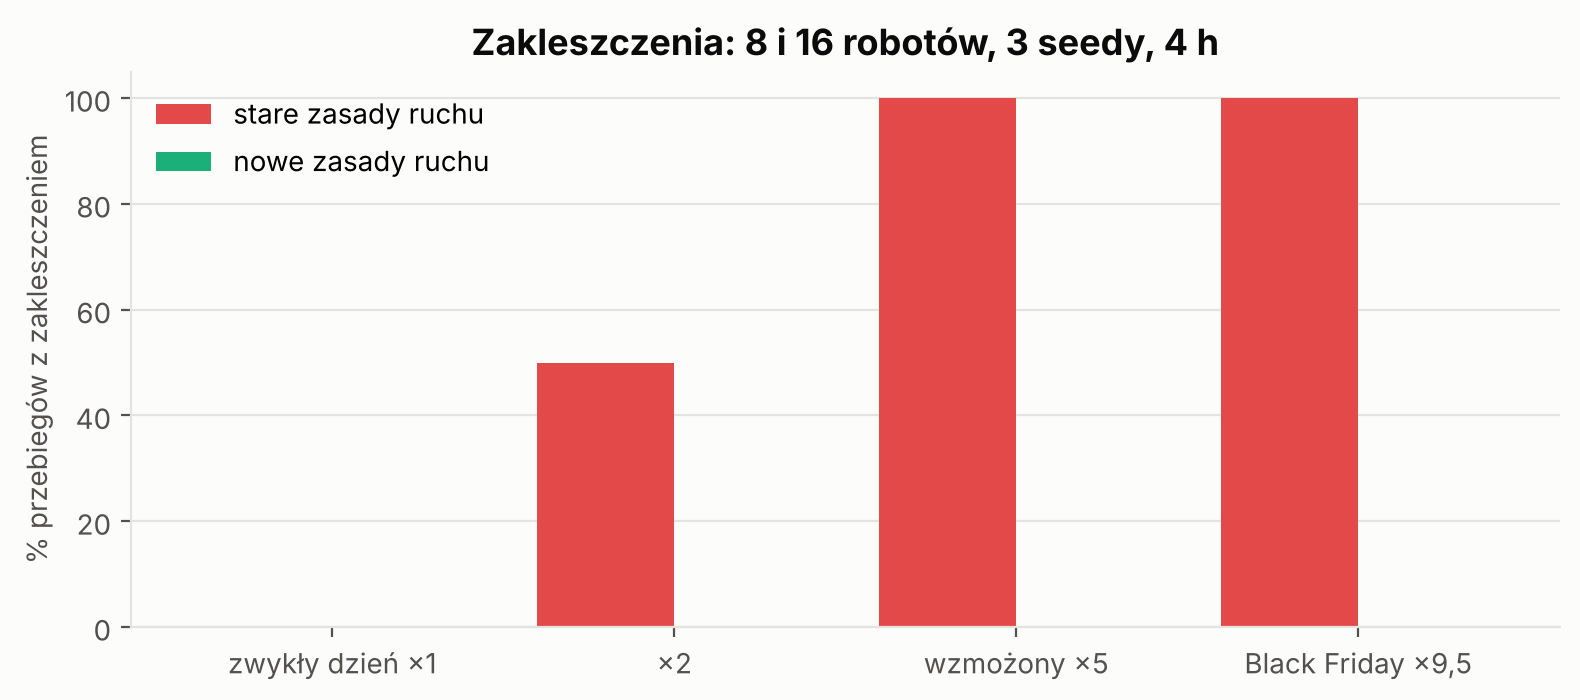

In [2]:
specs = [dict(num_robots=r, volume=v, seed=s, traffic=t)
         for t in ("old", "new") for r in (8, 16) for v in (1.0, 2.0, 5.0, 9.5) for s in (1, 2, 3)]
e0 = run_grid(specs, OUT / "e0_zakleszczenia.csv", jobs=JOBS)
e0["zakleszczenie"] = e0["status"].isin(["deadlock", "livelock"])
t0 = e0.groupby(["traffic", "volume"])["zakleszczenie"].mean().mul(100).unstack(0)[["old", "new"]]

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(t0))
ax.bar(x - 0.2, t0["old"], 0.4, color=CATEGORICAL[7], label="stare zasady ruchu")
ax.bar(x + 0.2, t0["new"], 0.4, color=CATEGORICAL[2], label="nowe zasady ruchu")
ax.set_xticks(x, [LOAD.get(v, f"×{v:g}") for v in t0.index])
ax.set_ylabel("% przebiegów z zakleszczeniem")
ax.set_ylim(0, 105)
ax.set_title("Zakleszczenia: 8 i 16 robotów, 3 seedy, 4 h")
ax.grid(axis="x", visible=False)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "e0_zakleszczenia.png", dpi=150)
t0.round(0)

## 1. Rozmieszczenie produktów (S1)

Losowe, ABC (najpopularniejsze najbliżej stanowisk) i losowe z odstawianiem regału na najbliższe
wolne miejsce. 8 robotów, 5 seedów, zwykły dzień i wzmożony ruch. Ten sam seed = te same zamówienia
we wszystkich wariantach. Paski błędów: 95% przedział ufności po seedach.

,volume,wariant,ok,runs,avg_completion_s,max_completion_s,distance_per_order_m,traffic_share_pct,racks_home_pct
0,1.0,losowe,5,5,28.1,73.7,49.1,6.3e-02,100.0
1,5.0,losowe,5,5,142.9,577.3,55.3,1.0e+00,100.0
2,1.0,ABC,5,5,24.2,67.9,40.0,5.4e-02,100.0
3,5.0,ABC,5,5,49.7,261.9,44.7,1.3e+00,100.0
4,1.0,losowe + najbliższe wolne,5,5,28.1,67.2,49.5,6.4e-02,51.0
5,5.0,losowe + najbliższe wolne,5,5,161.4,643.9,56.1,1.1e+00,6.0


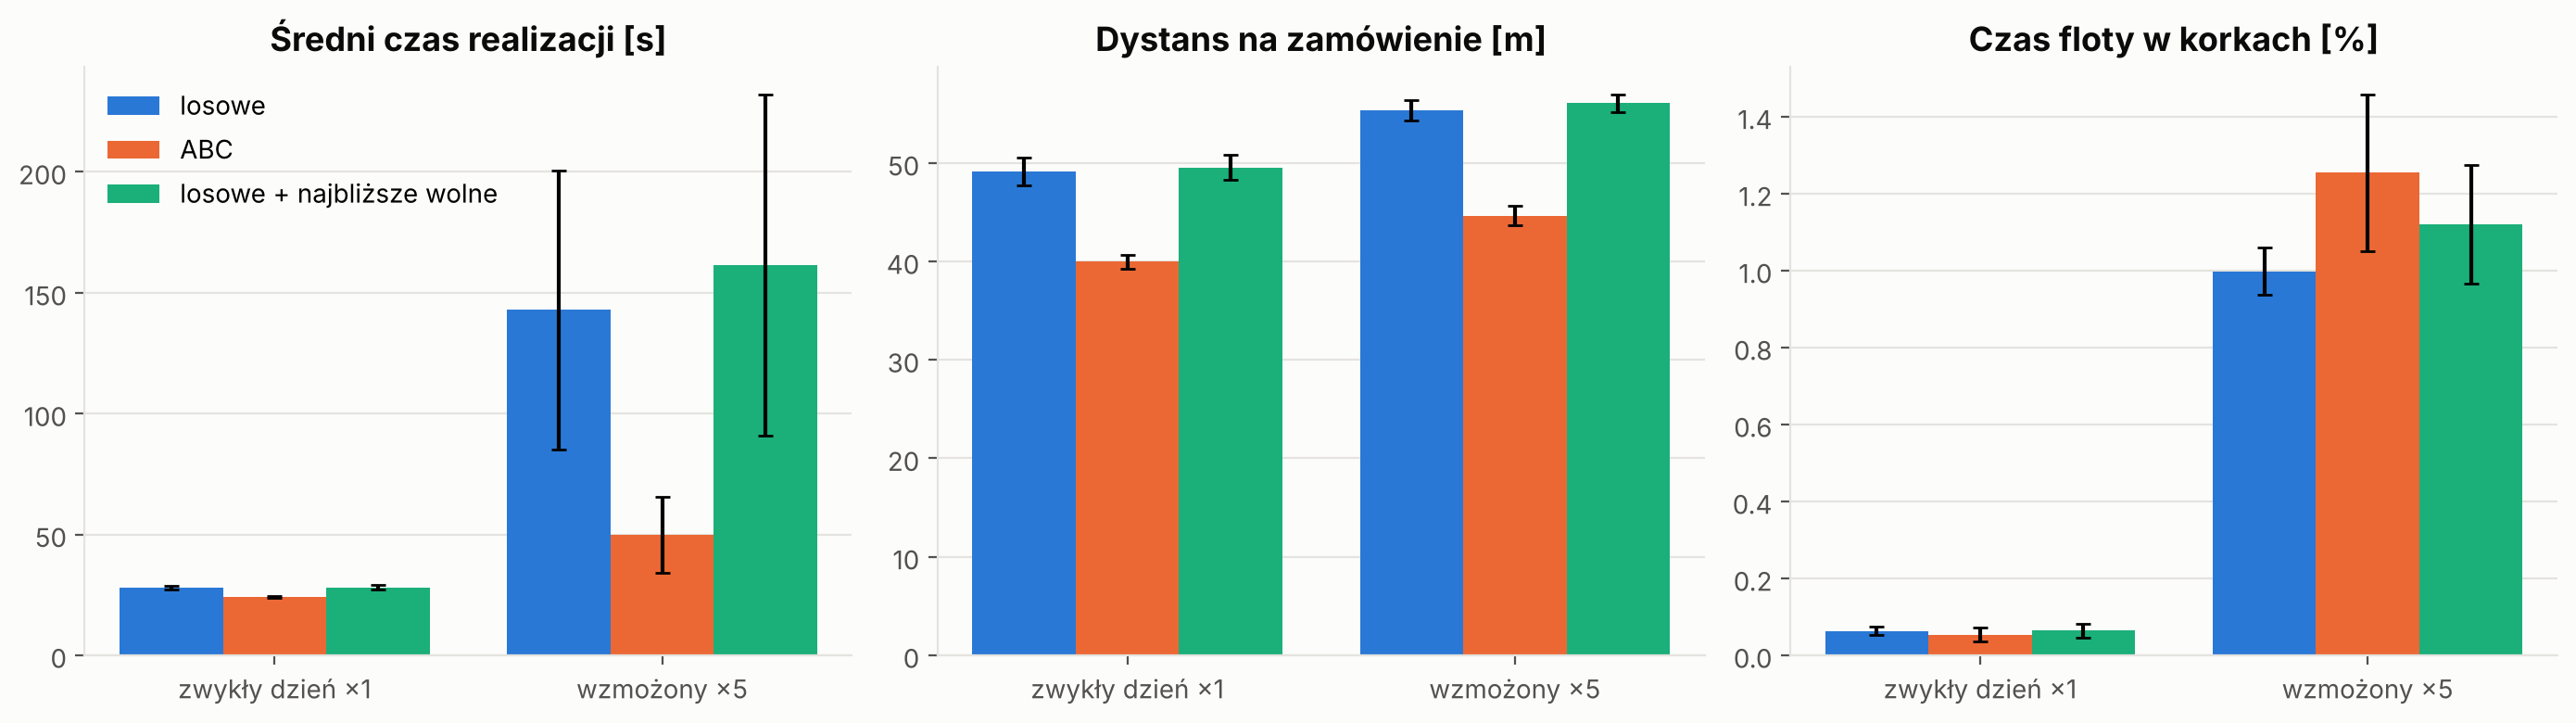

In [3]:
PLACEMENTS = {("random", "home"): "losowe", ("ABC", "home"): "ABC", ("random", "nearest"): "losowe + najbliższe wolne"}
specs = [dict(placement=p, return_policy=rp, volume=v, seed=s)
         for (p, rp) in PLACEMENTS for v in (1.0, 5.0) for s in range(1, 6)]
e1 = run_grid(specs, OUT / "e1_rozmieszczenie.csv", jobs=JOBS)
e1["wariant"] = [PLACEMENTS[(p, rp)] for p, rp in zip(e1.placement, e1.return_policy)]
METRICS = ["avg_completion_s", "max_completion_s", "distance_per_order_m", "traffic_share_pct", "racks_home_pct"]
t1 = summary(e1, ["volume", "wariant"], METRICS)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (metric, title) in zip(axes, [("avg_completion_s", "Średni czas realizacji [s]"),
                                      ("distance_per_order_m", "Dystans na zamówienie [m]"),
                                      ("traffic_share_pct", "Czas floty w korkach [%]")]):
    bars(ax, t1, "volume", "wariant", metric)
    ax.set_title(title)
axes[0].legend()
fig.tight_layout()
fig.savefig(OUT / "e1_rozmieszczenie.png", dpi=150)
t1[["volume", "wariant", "ok", "runs"] + METRICS]

## 2. Ile robotów potrzeba (S1): wzmożony ruch i Black Friday

Średni czas realizacji w zależności od liczby robotów. Przy Black Friday kolejka zamówień rośnie,
a czas realizacji to głównie czekanie na wolnego robota: od pewnej liczby robotów dokładanie
kolejnych pomaga coraz mniej. Przy Black Friday stanowiska są zajęte tylko ok. 50% czasu: wąskim
gardłem jest dojazd do nich (jedno pole wjazdu i wyjazdu, następny robot czeka, aż poprzedni wyjedzie;
`docs/decyzje_dane_olist.md`, sekcja 10).

,volume,placement,num_robots,ok,runs,avg_completion_s,avg_completion_s_ci,avg_wait_for_robot_s,avg_wait_for_robot_s_ci,station_utilisation_pct,station_utilisation_pct_ci,orders_per_hour,orders_per_hour_ci
0,5.0,random,4,3,3,1091.4,100.7,1056.7,100.6,21.8,1.1,230.8,2.2
1,5.0,ABC,4,3,3,880.2,179.2,850.0,179.2,23.9,1.3,253.6,3.4
2,5.0,random,8,3,3,124.1,131.7,87.8,130.5,30.8,2.0,325.3,10.9
3,5.0,ABC,8,3,3,42.4,18.4,11.2,15.6,31.5,2.6,332.0,16.5
4,5.0,random,12,3,3,38.0,4.8,3.2,1.9,31.8,2.8,334.6,18.3
5,5.0,ABC,12,3,3,33.4,5.8,2.6,1.8,31.8,2.9,335.2,19.1
6,5.0,random,16,3,3,36.0,3.9,2.0,0.8,31.8,2.8,334.8,18.4
7,5.0,ABC,16,3,3,32.2,5.5,1.8,0.7,31.8,2.9,335.2,19.1
8,5.0,random,24,3,3,34.7,4.4,1.6,0.7,31.8,2.8,334.9,18.7
9,5.0,ABC,24,3,3,31.1,4.4,1.7,0.5,31.8,2.9,335.2,18.7


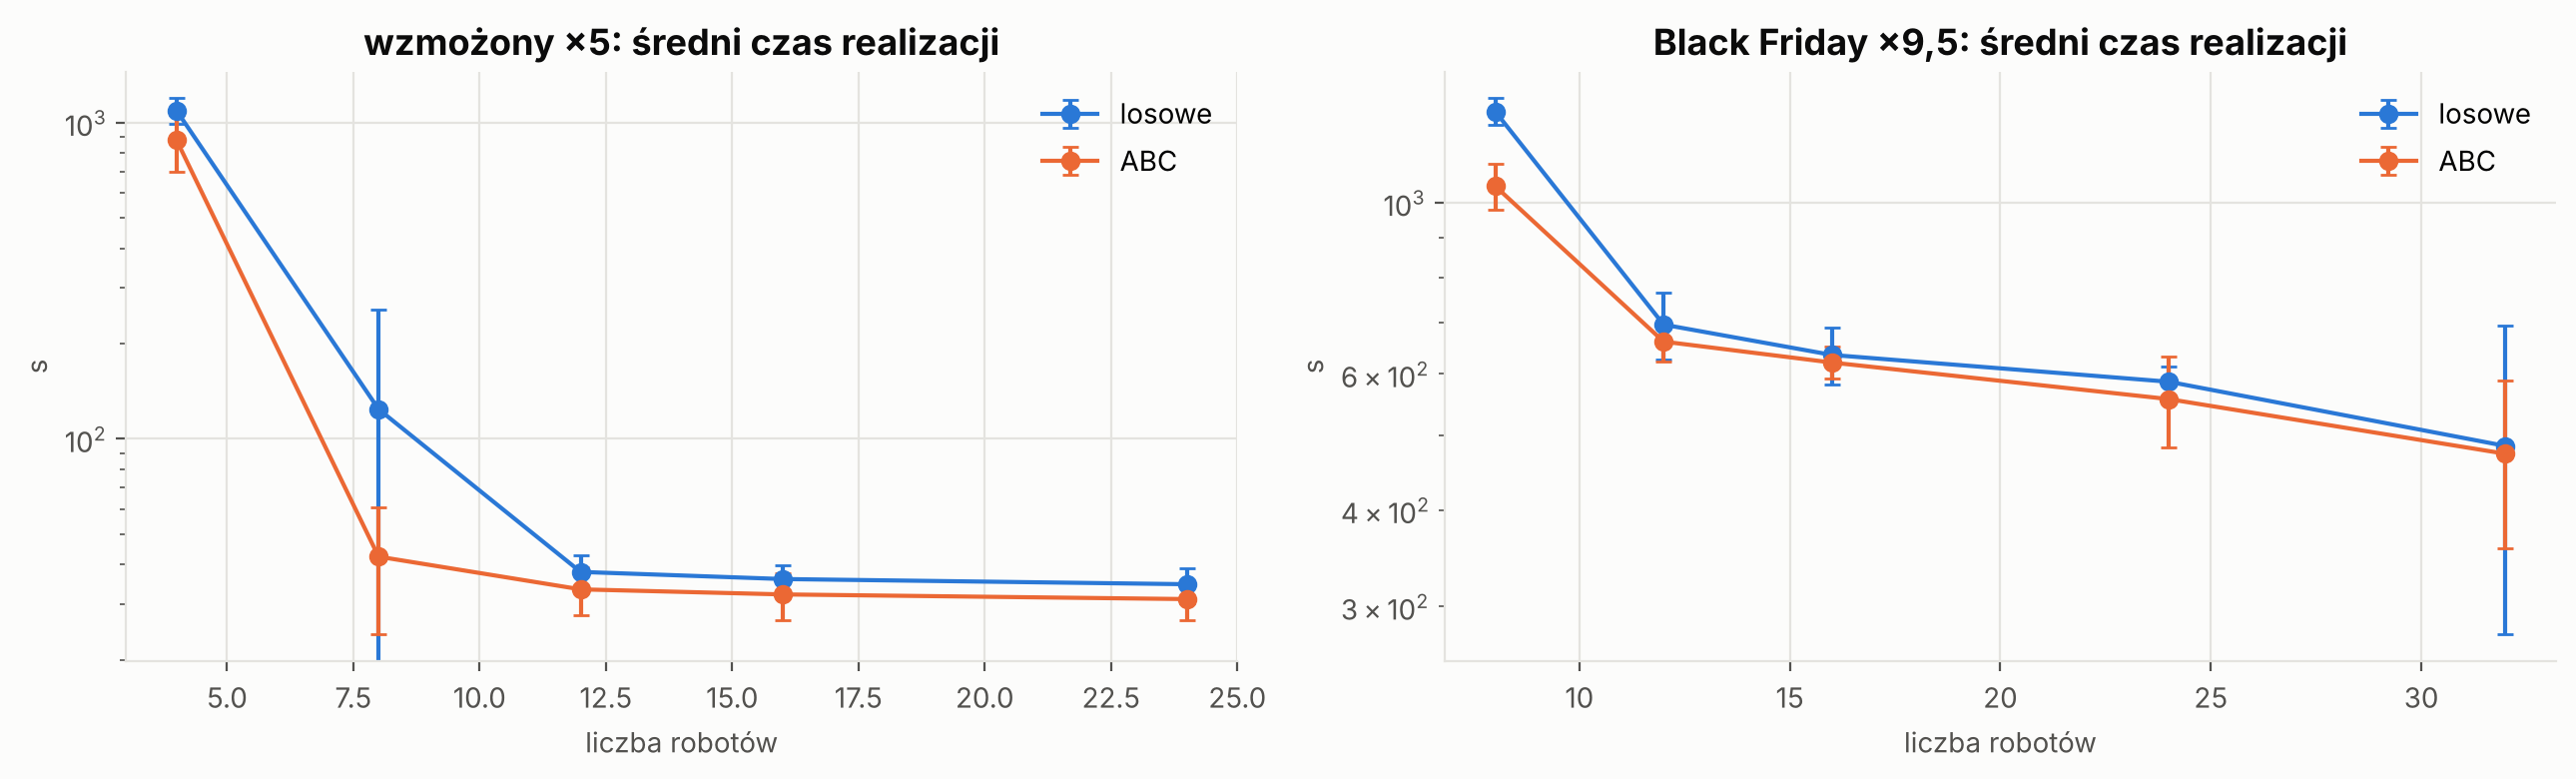

In [4]:
specs = [dict(num_robots=r, placement=p, volume=v, seed=s)
         for v, robots in ((5.0, (4, 8, 12, 16, 24)), (9.5, (8, 12, 16, 24, 32)))
         for r in robots for p in ("random", "ABC") for s in (1, 2, 3)]
e2 = run_grid(specs, OUT / "e2_roboty.csv", jobs=JOBS)
t2 = summary(e2, ["volume", "placement", "num_robots"], ["avg_completion_s", "avg_wait_for_robot_s", "station_utilisation_pct", "orders_per_hour"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, volume in zip(axes, (5.0, 9.5)):
    for color, placement in zip(CATEGORICAL, ("random", "ABC")):
        part = t2[(t2.volume == volume) & (t2.placement == placement)]
        ax.errorbar(part.num_robots, part.avg_completion_s, yerr=part.avg_completion_s_ci,
                    marker="o", capsize=3, color=color, label="losowe" if placement == "random" else "ABC")
    ax.set_title(f"{LOAD[volume]}: średni czas realizacji")
    ax.set_xlabel("liczba robotów")
    ax.set_ylabel("s")
    ax.set_yscale("log")
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / "e2_roboty.png", dpi=150)
t2

## 3. Przydział zadań (S6): najbliższy robot vs termin i bateria

16 robotów, 5 seedów. `deadline_battery` wybiera robota z uwzględnieniem terminu wysyłki
i poziomu baterii (`src/strategies/assignment.py`).

,volume,assignment,ok,runs,avg_completion_s,avg_completion_s_ci,max_completion_s,max_completion_s_ci,distance_per_order_m,distance_per_order_m_ci
0,5.0,nearest,5,5,36.2,1.5,207.7,45.4,48.7,0.8
1,9.5,nearest,5,5,633.7,21.4,3508.7,1170.9,55.7,0.8
2,5.0,deadline_battery,5,5,36.9,1.6,264.6,97.1,49.5,0.9
3,9.5,deadline_battery,5,5,639.6,34.0,4071.7,1229.5,56.3,0.7


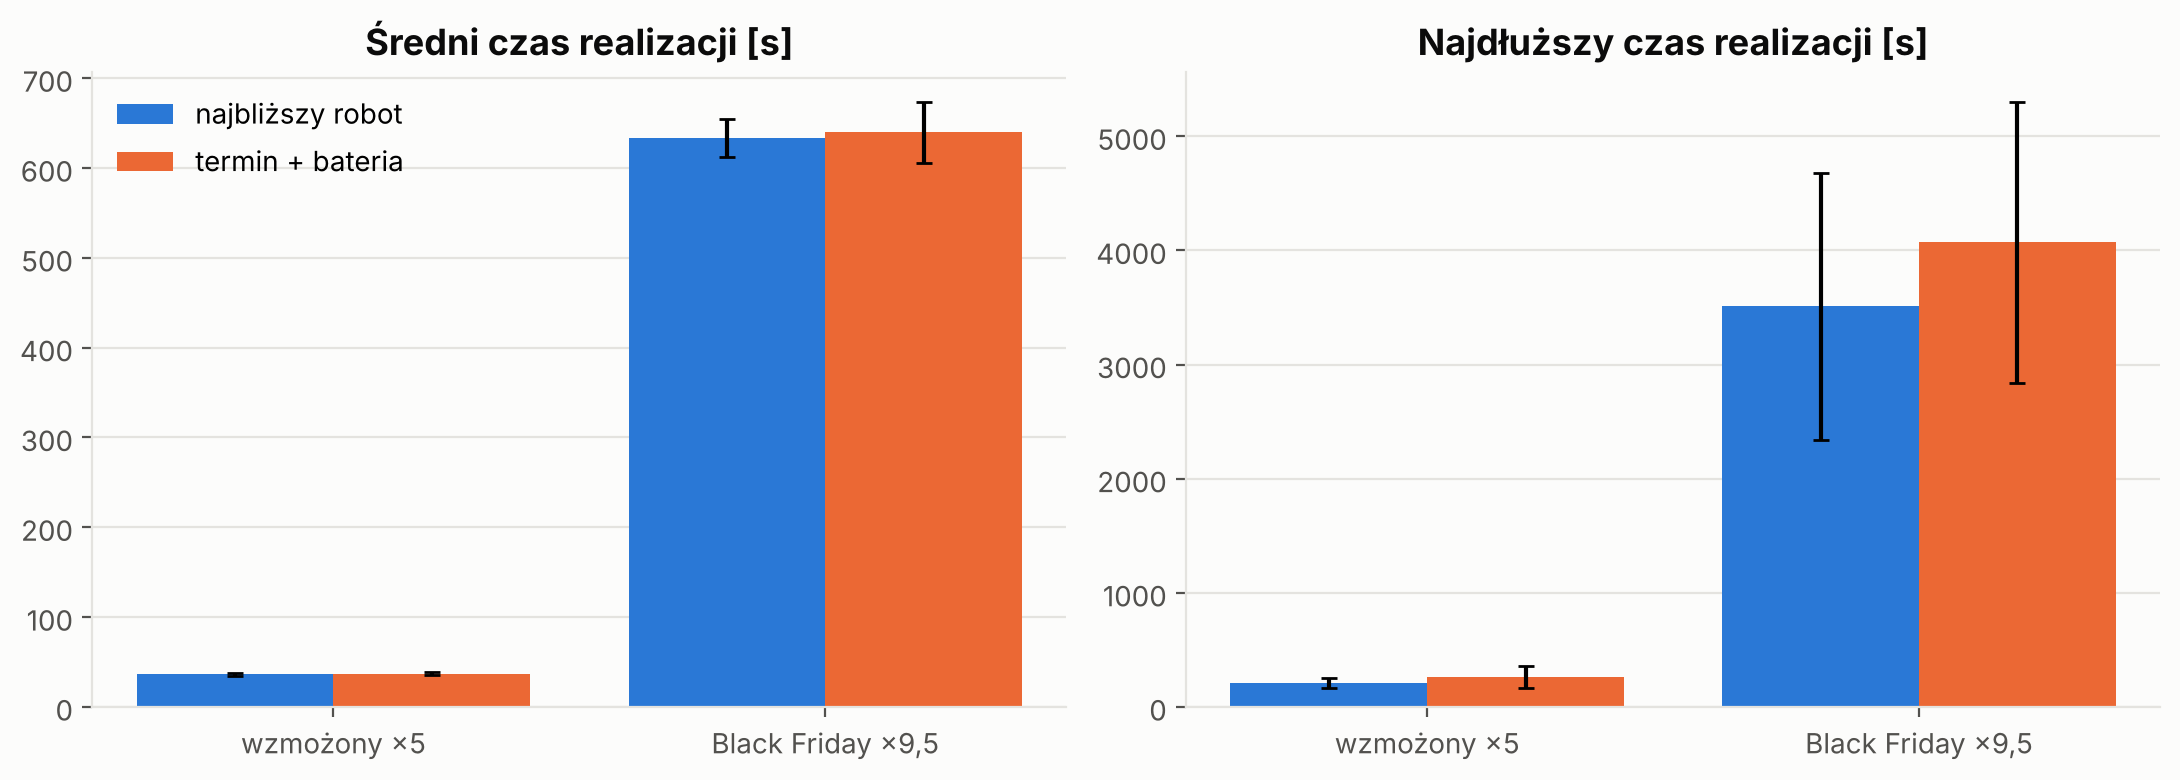

In [5]:
specs = [dict(num_robots=16, assignment=a, volume=v, seed=s)
         for a in ("nearest", "deadline_battery") for v in (5.0, 9.5) for s in range(1, 6)]
e3 = run_grid(specs, OUT / "e3_przydzial.csv", jobs=JOBS)
t3 = summary(e3, ["volume", "assignment"], ["avg_completion_s", "max_completion_s", "distance_per_order_m"])
names = {"nearest": "najbliższy robot", "deadline_battery": "termin + bateria"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (metric, title) in zip(axes, [("avg_completion_s", "Średni czas realizacji [s]"),
                                      ("max_completion_s", "Najdłuższy czas realizacji [s]")]):
    bars(ax, t3, "volume", "assignment", metric, labels=names)
    ax.set_title(title)
axes[0].legend()
fig.tight_layout()
fig.savefig(OUT / "e3_przydzial.png", dpi=150)
t3

## 4. Dodatkowo: układy magazynu (pliki `layouts/*.json`)

Ten sam strumień zamówień (wzmożony ruch ×5), ABC, 8 robotów, 3 seedy. Magazyny różnią się liczbą
regałów i stanowisk, więc to porównanie geometrii hali, a nie jednej zmiennej. W temacie projektu
tego nie ma; do decyzji z prowadzącym, czy włączać.

,layout,ok,runs,avg_completion_s,avg_completion_s_ci,distance_per_order_m,distance_per_order_m_ci,traffic_share_pct,traffic_share_pct_ci,station_utilisation_pct,station_utilisation_pct_ci
0,demo_20x20,3,3,35.7,8.4,37.0,0.4,1.1,0.2,31.7,2.9
1,dwie_hale,3,3,147.1,117.6,58.9,1.1,0.6,0.2,20.4,1.6
2,hala_L,3,3,28.7,3.1,34.8,0.3,0.7,0.4,21.2,1.9
3,kiva_standard,3,3,42.4,18.4,44.1,0.8,1.2,0.4,31.5,2.6
4,szerokie_alejki,3,3,29.4,3.6,37.2,0.5,0.4,0.2,21.2,1.9


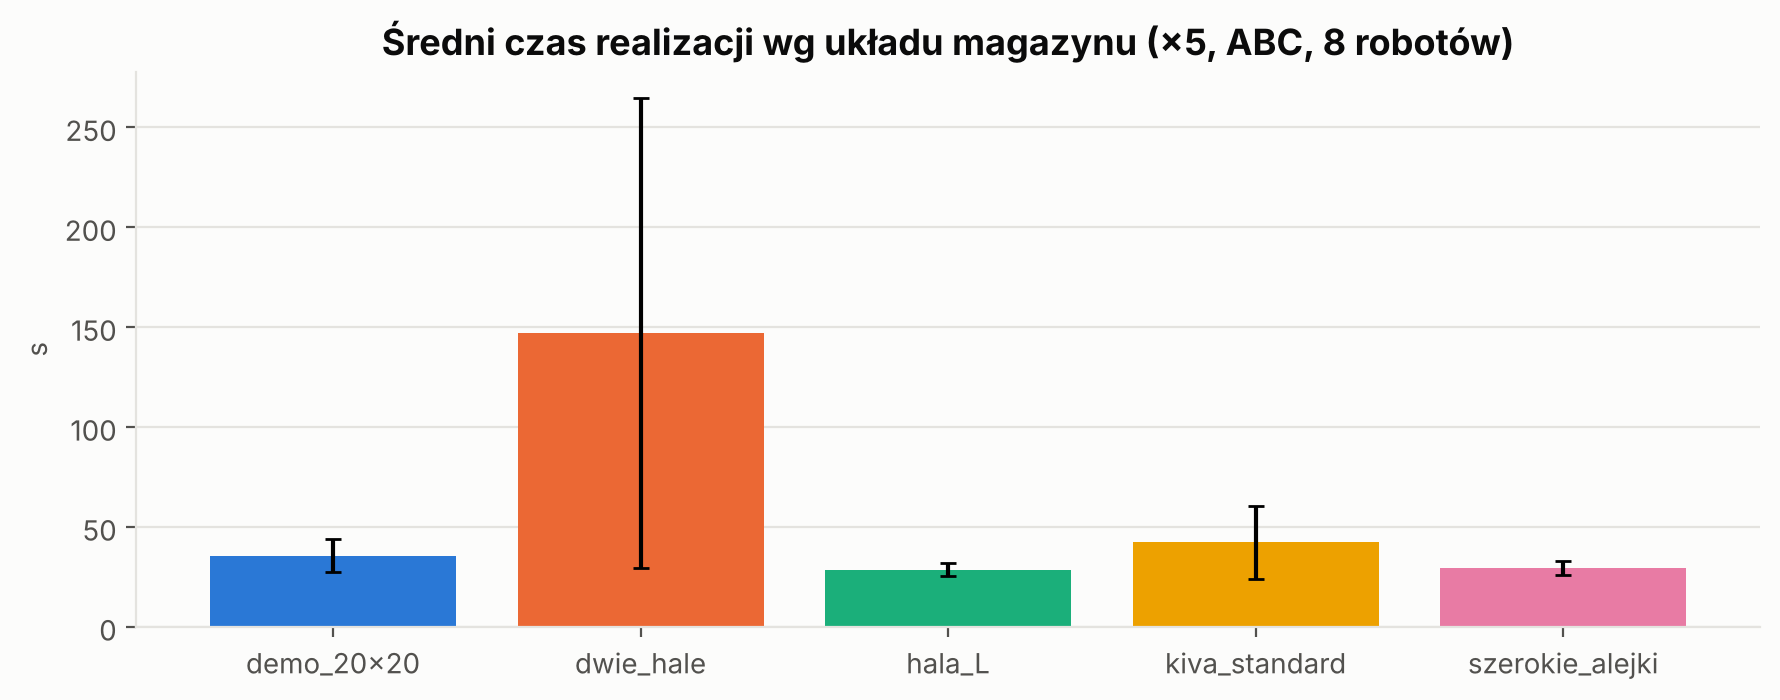

In [6]:
specs = [dict(layout=key, placement="ABC", volume=5.0, seed=s) for key in LAYOUTS for s in (1, 2, 3)]
e4 = run_grid(specs, OUT / "e4_uklady.csv", jobs=JOBS)
t4 = summary(e4, ["layout"], ["avg_completion_s", "distance_per_order_m", "traffic_share_pct", "station_utilisation_pct"])

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(t4.layout, t4.avg_completion_s, yerr=t4.avg_completion_s_ci, capsize=3, color=CATEGORICAL[: len(t4)])
ax.set_ylabel("s")
ax.set_title("Średni czas realizacji wg układu magazynu (×5, ABC, 8 robotów)")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(OUT / "e4_uklady.png", dpi=150)
t4

## 5. Najważniejsze różnice w liczbach

Liczone z tabel powyżej (średnie po seedach, tylko przebiegi bez zakleszczenia).

In [7]:
def change(table, by, base, other, metric, **where):
    part = table
    for key, value in where.items():
        part = part[part[key] == value]
    a = part[part[by] == base][metric].iloc[0]
    b = part[part[by] == other][metric].iloc[0]
    return f"{a:.1f} → {b:.1f} ({100 * (b - a) / a:+.0f}%)"

rows = []
for v in (1.0, 5.0):
    for metric, name in [("avg_completion_s", "średni czas [s]"), ("distance_per_order_m", "dystans/zam. [m]"),
                         ("traffic_share_pct", "korki [% czasu floty]")]:
        rows.append({"porównanie": f"losowe → ABC, {LOAD[v]}", "miara": name,
                     "zmiana": change(t1, "wariant", "losowe", "ABC", metric, volume=v)})
for v in (5.0, 9.5):
    rows.append({"porównanie": f"najbliższy → termin+bateria, {LOAD[v]}", "miara": "średni czas [s]",
                 "zmiana": change(t3, "assignment", "nearest", "deadline_battery", "avg_completion_s", volume=v)})
pd.DataFrame(rows)

,porównanie,miara,zmiana
0,"losowe → ABC, zwykły dzień ×1",średni czas [s],28.1 → 24.2 (-14%)
1,"losowe → ABC, zwykły dzień ×1",dystans/zam. [m],49.1 → 40.0 (-19%)
2,"losowe → ABC, zwykły dzień ×1",korki [% czasu floty],0.1 → 0.1 (-15%)
3,"losowe → ABC, wzmożony ×5",średni czas [s],142.9 → 49.7 (-65%)
4,"losowe → ABC, wzmożony ×5",dystans/zam. [m],55.3 → 44.7 (-19%)
5,"losowe → ABC, wzmożony ×5",korki [% czasu floty],1.0 → 1.3 (+26%)
6,"najbliższy → termin+bateria, wzmożony ×5",średni czas [s],36.2 → 36.9 (+2%)
7,"najbliższy → termin+bateria, Black Friday ×9,5",średni czas [s],633.7 → 639.6 (+1%)
